# YOLO26s: detect the lesion, crop it, classify the crop  (notebook 2 of 2)

This notebook runs the **whole pipeline with YOLO26s only**: a YOLO26s *detector* and a YOLO26s *classifier*, trained from the pretrained ImageNet/COCO weights, on the **original (unsegmented) photos**. It runs **on its own**, so it can run at the same time as the YOLO26n notebook. When both have finished, the small compare notebook puts YOLO26n, YOLO26s and your Stage 5 model in one set of graphs.

Two stages, using your COCO lesion annotations:

| Stage | Model | Trained on | Output |
|---|---|---|---|
| 1. Detector | YOLO26 detection (`yolo26s.pt`) | your COCO boxes: **Lesion** and **Oral Cavity** | boxes + confidence |
| 2. Classifier | YOLO26 classification (`yolo26s-cls.pt`) | square crops around the annotated lesions (Healthy images: the oral-cavity crop) | Benign / Healthy / OCA / OPMD |

**How one photo is classified at test time (no annotations are used):**
1. The detector finds lesion boxes. The top 3 boxes above the confidence threshold are cropped.
2. The classifier predicts each crop; the photo's class probabilities are the confidence-weighted average.
3. If no lesion is found, the detected oral-cavity box is cropped instead (this is how a Healthy photo is classified).
   If that also fails, the whole photo is used. The report shows how often each case happened.

**Same rules as the earlier notebooks**
- Same patient-level split (`split_assignment.csv`), checked against `patient_split_summary.csv`; no patient is in two splits.
- Your offline augmentation recipe (flip, rotation, zoom 0.75x-1.2x, brightness, contrast, saturation, white balance,
  blur, noise; no hue change) is applied to the **training crops of OCA only, 4 new copies each**. Val/test are never augmented.
- Each model's checkpoint is chosen on validation data inside training; the pipeline to carry forward is chosen by
  **validation macro-F1** (tie-break: smaller train/val gap). Test is reported, never used to choose.
- The annotations are used only to **train** the models and for the clearly labelled "GT boxes (upper bound)" row,
  which shows what a perfect detector would give. That row is not a real result because new photos have no annotations.

**Saved for the fusion notebooks (per pipeline):** `<tag>_embeddings.npy` + `<tag>_embeddings_meta.csv` (one row per photo,
the confidence-weighted mean of its crop embeddings), `<tag>_probabilities.csv`, the detector and classifier weights,
`<tag>_model_config.json`, and `fusion_manifest.json`.


In [1]:
# ============================================================
# 1. CONFIG -- EDIT THE PATHS FOR YOUR KAGGLE NOTEBOOK
# ============================================================
from pathlib import Path
import json as _json, os, re, shutil, sys, time, subprocess

# ---------------- DATA ----------------
SPLIT_ASSIGNMENT_CSV = Path("/kaggle/input/datasets/gokulkrishnabr/csv-for-yolo-26/split_assignment.csv")       # image_name, patient_id, category, split
PATIENT_SPLIT_CSV    = Path("/kaggle/input/datasets/gokulkrishnabr/csv-for-yolo-26/patient_split_summary.csv")  # patient_id, split (cross-check)
ANNOTATION_JSON      = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json")             # COCO: categories Lesion, Oral Cavity
UNSEGMENTED_ROOT     = Path("/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project")                            # folders Benign / Healthy / OCA / OPMD

# ---------------- STAGE 1: detector ----------------
DET_MODELS = ["yolo26s.pt"]            # this notebook: YOLO26s only
DET_MAX_SIDE = 1280                    # originals are resized ONCE so the longer side is this many pixels
DET_IMGSZ = 640
DET_EPOCHS = 100
DET_PATIENCE = 20
DET_BATCH = 16
MIN_BOX_PX = 8                         # lesion boxes smaller than this (after resizing) are dropped
# ---------------- STAGE 2: classifier ----------------
CLS_MODELS = ["yolo26s-cls.pt"]
CLS_IMGSZ = 224
CLS_EPOCHS = 100
CLS_PATIENCE = 15
CLS_BATCH = 32
CROP_SIZE = 256                        # saved crops are square, this many pixels
CROP_MARGIN = 0.15                     # context added around a box (fraction of its size, each side)
AUG_PER_CROP = {"Healthy": 0, "Benign": 0, "OPMD": 0, "OCA": 4}   # YOUR recipe: OCA x4 new copies, train only
# ---------------- PIPELINE ----------------
CONF_THR = 0.25                        # lesion boxes below this confidence are ignored
TOP_K = 3                              # at most this many lesion boxes per photo are classified
SEED = 0
WORKERS = 2
SAFE_AUGMENTATION = dict(fliplr=0.5, flipud=0.0, hsv_h=0.0, hsv_s=0.2, hsv_v=0.2)   # clinically safe, no hue shift
WEIGHTS_DIR = None                     # folder holding the .pt files if Kaggle internet is off
SESSION_BUDGET_MINUTES = 660
# If a run stopped after training, reuse its trained weights instead of training again: add that run's OUTPUT as an input
# ("Add Input" -> "Notebook Output Files") and set this to its folder. It is searched for det__*/weights/best.pt and cls__*/weights/best.pt.
RESUME_FROM = None                     # a folder, or a list of folders, e.g. [Path("/kaggle/input/notebooks/<you>/<notebook>")]
TRAIN_DET_IF_MISSING = True            # False = never train the detector here; stop with a clear message if no trained one is found
TRAIN_CLS_IF_MISSING = True            # same for the classifier

OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# image copies/crops go to local scratch disk, NOT /kaggle/working, so they are not saved with the notebook output
WORK = (Path("/kaggle/temp") if Path("/kaggle/temp").is_dir() else Path("/tmp")) / "detcls_work"
RUNS_DIR = OUTPUT_DIR / "detcls_runs"
WORK.mkdir(parents=True, exist_ok=True)

# ---------------- COMPARISON REFERENCES ----------------
STAGE5_REFERENCE = {
    "val_accuracy": 0.5899, "val_macro_f1": 0.4641, "test_accuracy": 0.5600, "test_macro_f1": 0.5014,
    "train_val_gap": 0.3323, "train_accuracy": 0.9222,
    "n_params": 4_050_000, "file_mb": 16.5,       # EfficientNetB0 + plain head, approximate
    "test_f1_by_class": {"Benign": 0.48, "Healthy": 0.58, "OCA": 0.32, "OPMD": 0.63},
}
# Optional: yolo_final_results.csv from the whole-image YOLO26 classification notebook, to show it in the same table.
YOLO_WHOLE_IMAGE_CSV = None            # e.g. Path("/kaggle/input/<yolo-output>/yolo_final_results.csv")
# Optional: the OUTPUT folder of the other YOLO-version notebook (it must contain detcls_final_results.csv and *_final_metrics.json).
# Its best pipeline is then shown next to this one and Stage 5 in the comparison figures.
OTHER_RUN_DIR = None                   # optional: leave None; the n-vs-s comparison is done by the separate compare notebook

for _p in (SPLIT_ASSIGNMENT_CSV, PATIENT_SPLIT_CSV, ANNOTATION_JSON):
    assert _p.is_file(), f"{_p} not found -- attach the dataset and fix the path in CONFIG."
assert UNSEGMENTED_ROOT.is_dir(), f"{UNSEGMENTED_ROOT} not found -- fix UNSEGMENTED_ROOT."
print("Config OK. Detectors:", DET_MODELS, " Classifiers:", CLS_MODELS)


Config OK. Detectors: ['yolo26s.pt']  Classifiers: ['yolo26s-cls.pt']


In [2]:
# ============================================================
# 2. SETUP -- YOLO26 needs Ultralytics >= 8.4 (Kaggle needs Internet ON to install it and download the weights)
# ============================================================
from importlib.metadata import version as _pkg_version, PackageNotFoundError
from packaging.version import Version

try:
    _have = Version(_pkg_version("ultralytics"))
except PackageNotFoundError:
    _have = Version("0")
if _have < Version("8.4.0"):
    print(f"Installing/upgrading ultralytics (found {_have}) ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "ultralytics"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker
import matplotlib.patches
import ultralytics
from ultralytics import YOLO
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import gc, psutil, torch

def mem(tag=""):
    # memory use printed at key points, to show where a crash would come from (RAM = main memory, GPU = graphics memory)
    ram = psutil.Process().memory_info().rss / 1e9
    tot = psutil.virtual_memory().total / 1e9
    gpu = (torch.cuda.memory_allocated() / 1e9) if torch.cuda.is_available() else 0.0
    print(f"  [memory {tag}] RAM {ram:.1f} / {tot:.1f} GB   GPU allocated {gpu:.1f} GB")

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("ultralytics", ultralytics.__version__)
mem("start")


Installing/upgrading ultralytics (found 0) ...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 4.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.174
  [memory start] RAM 0.8 / 33.7 GB   GPU allocated 0.0 GB


In [3]:
# ============================================================
# 3. DATA PREPARATION
#    a) patient-level split from your CSVs (checked)        b) originals + COCO boxes, matched by image name
#    c) detector dataset: resized photos + YOLO box labels  d) classifier dataset: square crops around the boxes,
#       with your augmentation recipe on the OCA training crops
# ============================================================
from PIL import Image, ImageOps, ImageFilter, ImageEnhance, ImageFile
from concurrent.futures import ThreadPoolExecutor

ImageFile.LOAD_TRUNCATED_IMAGES = True      # a few photos in a large dataset can be cut short; load what is there instead of crashing

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
SPLITS = ("train", "val", "test")
DET_CLASSES = ["Lesion", "Oral Cavity"]


def norm_key(stem):
    # "R-01-02", "r_1_2", "R-01-02.jpg" all become ("r", 1, 2); anything else falls back to its lower-case name.
    s = re.sub(r"\.[A-Za-z]{3,4}$", "", str(stem).strip())
    s = re.sub(r"[-_ ]?(segmented|seg|masked|mask)$", "", s.lower())
    m = re.match(r"^([a-z]+)[-_ ]?0*(\d+)(?:[-_ ]0*(\d+))?$", s)
    if m:
        return (m.group(1), int(m.group(2)), int(m.group(3)) if m.group(3) else -1)
    return (s,)


# ---- a) patient-level split ----
split_df = pd.read_csv(SPLIT_ASSIGNMENT_CSV, usecols=["image_name", "patient_id", "category", "split"])
split_df["image_name"] = split_df["image_name"].astype(str)
split_df["split"] = split_df["split"].str.strip().str.lower()
print(f"Patient-level split file: {len(split_df)} images, {split_df.patient_id.nunique()} patients ({split_df.split.value_counts().to_dict()})")
_pp = split_df.groupby("patient_id")["split"].nunique()
assert _pp.max() == 1, f"patients in more than one split: {_pp[_pp > 1].index.tolist()[:5]}"
_summ = pd.read_csv(PATIENT_SPLIT_CSV)[["patient_id", "split"]].rename(columns={"split": "split_summary"})
_chk = split_df.groupby("patient_id")["split"].first().reset_index().merge(_summ, on="patient_id", how="outer")
assert not _chk["split"].ne(_chk["split_summary"]).any(), "the two split files disagree on some patients"
print("Patient-level check OK: every patient is in exactly one split and both files agree.")
split_df["key"] = split_df["image_name"].map(norm_key)

# ---- b) originals and COCO annotations ----
index, n_dupname = {}, 0
for f in UNSEGMENTED_ROOT.rglob("*"):
    if f.is_file() and f.suffix.lower() in IMG_EXT:
        k = norm_key(f.stem)
        if k in index:
            n_dupname += 1
        else:
            index[k] = f
print(f"Original photos found: {len(index)} unique names ({n_dupname} duplicate names ignored)")

coco = _json.load(open(ANNOTATION_JSON))
_cat = {c["id"]: c["name"] for c in coco["categories"]}
assert set(_cat.values()) >= set(DET_CLASSES), f"annotation categories {_cat} do not include {DET_CLASSES}"
_img_key = {i["id"]: norm_key(i["file_name"]) for i in coco["images"]}
ann_by_key = {}
for a in coco["annotations"]:
    x, y, w, h = a["bbox"]
    if _cat[a["category_id"]] in DET_CLASSES and w > 0 and h > 0:
        ann_by_key.setdefault(_img_key[a["image_id"]], {"Lesion": [], "Oral Cavity": []})[_cat[a["category_id"]]].append([x, y, x + w, y + h])

split_df["src"] = split_df["key"].map(index.get)
split_df["has_ann"] = split_df["key"].map(lambda k: k in ann_by_key)
rate = (split_df["src"].notna() & split_df["has_ann"]).mean()
print(f"Photos with both an original file and annotations: {rate:.1%}")
assert rate >= 0.95, ("Fewer than 95% matched. Unmatched examples: "
                      f"{split_df.loc[split_df.src.isna() | ~split_df.has_ann, 'image_name'].head(8).tolist()} -- adjust norm_key().")
split_df = split_df[split_df["src"].notna() & split_df["has_ann"]].copy()
_bad = split_df["src"].map(lambda p: p.parent.name.lower()) != split_df["category"].str.lower()
if _bad.any():
    print(f"WARNING: {int(_bad.sum())} photos whose class folder disagrees with the CSV are dropped.")
    split_df = split_df[~_bad].copy()
CLASS_NAMES = sorted(split_df["category"].unique())
N_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

# ---- c) detector dataset ----
DET_DIR = WORK / "det"
CLS_DIR = WORK / "cls_crops"
for _s in SPLITS:
    (DET_DIR / "images" / _s).mkdir(parents=True, exist_ok=True)
    (DET_DIR / "labels" / _s).mkdir(parents=True, exist_ok=True)


def _fits(boxes, W, H, tol=3):
    return all(b[0] >= -tol and b[1] >= -tol and b[2] <= W + tol and b[3] <= H + tol for b in boxes)


def _prep_image(row):
    # Resize once; EXIF rotation is applied only if the annotation coordinates fit the rotated image
    # (COCO boxes are in the pixel grid the annotator saw).
    ann = ann_by_key[row["key"]]
    allb = ann["Lesion"] + ann["Oral Cavity"]
    dst = DET_DIR / "images" / row["split"] / (Path(row["src"]).stem + ".jpg")
    with Image.open(row["src"]) as im0:
        raw_size = im0.size
        im_t = ImageOps.exif_transpose(im0)
        if _fits(allb, *im_t.size):
            im, orient = im_t, "exif"
        elif _fits(allb, *raw_size):
            im, orient = im0, "raw"
        else:
            return dict(status="box_outside_image")
        im = im.convert("RGB")
        W, H = im.size
        sc = min(1.0, DET_MAX_SIDE / max(W, H))
        nw, nh = max(1, round(W * sc)), max(1, round(H * sc))
        if (nw, nh) != (W, H):
            im = im.resize((nw, nh), Image.LANCZOS)
        if not dst.exists():
            im.save(dst, quality=95)

    def clip(b):
        return [max(0.0, b[0] * sc), max(0.0, b[1] * sc), min(float(nw), b[2] * sc), min(float(nh), b[3] * sc)]
    les = [clip(b) for b in ann["Lesion"]]
    les = [b for b in les if (b[2] - b[0]) >= MIN_BOX_PX and (b[3] - b[1]) >= MIN_BOX_PX]
    cav = [clip(b) for b in ann["Oral Cavity"]]
    cav = cav[0] if cav else [0.0, 0.0, float(nw), float(nh)]
    lines = [f"1 {(cav[0] + cav[2]) / 2 / nw:.6f} {(cav[1] + cav[3]) / 2 / nh:.6f} {(cav[2] - cav[0]) / nw:.6f} {(cav[3] - cav[1]) / nh:.6f}"]
    for b in les:
        lines.append(f"0 {(b[0] + b[2]) / 2 / nw:.6f} {(b[1] + b[3]) / 2 / nh:.6f} {(b[2] - b[0]) / nw:.6f} {(b[3] - b[1]) / nh:.6f}")
    (DET_DIR / "labels" / row["split"] / (dst.stem + ".txt")).write_text("\n".join(lines) + "\n")
    return dict(status="ok", path=str(dst), W=nw, H=nh, lesions=les, cavity=cav, orient=orient)


def prep_image(row):
    try:
        return _prep_image(row)
    except Exception as e:                    # an unreadable photo is skipped and reported, never a crash
        return dict(status=f"unreadable: {type(e).__name__}: {e}"[:120])


print(f"Preparing {len(split_df)} photos (resize to a {DET_MAX_SIDE}px longer side, write YOLO labels) ...")
with ThreadPoolExecutor(max_workers=4) as ex:
    _res = list(ex.map(prep_image, [r for _, r in split_df.iterrows()]))
split_df["status"] = [r["status"] for r in _res]
_n_out = int((split_df["status"] != "ok").sum())
print(f"Photos skipped: {_n_out}  {split_df.loc[split_df['status'] != 'ok', 'status'].value_counts().to_dict() if _n_out else ''}")
if _n_out:
    print("  e.g.", split_df.loc[split_df["status"] != "ok", "image_name"].head(8).tolist())
assert _n_out <= 0.05 * len(split_df), "More than 5% of the photos were skipped -- the annotations may not match these originals, or many files are damaged."
imgs = split_df[split_df["status"] == "ok"].reset_index(drop=True)
_ok = [r for r in _res if r["status"] == "ok"]
for c in ("path", "W", "H", "lesions", "cavity", "orient"):
    imgs[c] = [r[c] for r in _ok]
imgs = imgs.drop(columns=["src", "has_ann", "status", "key"]).rename(columns={"path": "path"})
print("Orientation used:", imgs["orient"].value_counts().to_dict())
imgs["n_lesions"] = imgs["lesions"].map(len)
print("\nPhotos per split and class:")
print(imgs.groupby(["split", "category"]).size().unstack(fill_value=0).to_string())
print("\nLesion boxes per split and class (GT):")
print(imgs.groupby(["split", "category"])["n_lesions"].sum().unstack(fill_value=0).to_string())

DET_YAML = DET_DIR / "data.yaml"
DET_YAML.write_text(f"path: {DET_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: Lesion\n  1: Oral Cavity\n")


# ---- d) classifier dataset: square crops ----
def square_crop(img, box, margin=CROP_MARGIN, out=CROP_SIZE):
    W, H = img.size
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    side = min(max(box[2] - box[0], box[3] - box[1]) * (1 + 2 * margin), W, H)
    left = min(max(cx - side / 2, 0), W - side)
    top = min(max(cy - side / 2, 0), H - side)
    return img.crop((round(left), round(top), round(left + side), round(top + side))).resize((out, out), Image.LANCZOS)


# YOUR augmentation recipe (augmentation notebook / augmentation_types.csv), applied to training crops.
# hflip(p=.5) -> rotate +-15deg (black fill) -> zoom 0.75x-1.2x (out or in) -> brightness .8-1.2 -> contrast .8-1.2
# -> saturation .85-1.15 -> white balance R,B x .95-1.05 -> blur (p=.2, r .3-1) -> noise (p=.2, sigma 4) -> keep black fill black.
def augment_one(img, r):
    img = img.convert("RGB")
    w, h = img.size
    mask = Image.new("L", (w, h), 255)
    if r.random() < 0.5:
        img, mask = img.transpose(Image.FLIP_LEFT_RIGHT), mask.transpose(Image.FLIP_LEFT_RIGHT)
    ang = r.uniform(-15, 15)
    img = img.rotate(ang, resample=Image.BILINEAR, fillcolor=(0, 0, 0))
    mask = mask.rotate(ang, resample=Image.BILINEAR, fillcolor=0)
    z = r.uniform(0.75, 1.2)
    if z >= 1.0:
        cw, ch = max(1, int(w / z)), max(1, int(h / z))
        x0, y0 = r.integers(0, w - cw + 1), r.integers(0, h - ch + 1)
        img = img.crop((x0, y0, x0 + cw, y0 + ch)).resize((w, h), Image.BILINEAR)
        mask = mask.crop((x0, y0, x0 + cw, y0 + ch)).resize((w, h), Image.BILINEAR)
    else:
        nw_, nh_ = max(1, int(w * z)), max(1, int(h * z))
        x0, y0 = r.integers(0, w - nw_ + 1), r.integers(0, h - nh_ + 1)
        canvas, mcanvas = Image.new("RGB", (w, h), (0, 0, 0)), Image.new("L", (w, h), 0)
        canvas.paste(img.resize((nw_, nh_), Image.BILINEAR), (x0, y0))
        mcanvas.paste(mask.resize((nw_, nh_), Image.BILINEAR), (x0, y0))
        img, mask = canvas, mcanvas
    img = ImageEnhance.Brightness(img).enhance(r.uniform(0.8, 1.2))
    img = ImageEnhance.Contrast(img).enhance(r.uniform(0.8, 1.2))
    img = ImageEnhance.Color(img).enhance(r.uniform(0.85, 1.15))
    arr = np.asarray(img).astype(np.float32)
    arr[..., 0] *= r.uniform(0.95, 1.05)
    arr[..., 2] *= r.uniform(0.95, 1.05)
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    if r.random() < 0.2:
        img = img.filter(ImageFilter.GaussianBlur(r.uniform(0.3, 1.0)))
    if r.random() < 0.2:
        arr = np.asarray(img).astype(np.float32) + r.normal(0, 4.0, (h, w, 3))
        img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    arr = np.asarray(img).astype(np.float32)
    arr[np.asarray(mask) < 128] = 0
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))


aug_rng = np.random.default_rng(42)          # same seed as your augmentation notebook
gt_rows = []
for r in imgs.itertuples():
    boxes = [r.cavity] if r.category == "Healthy" else list(r.lesions)     # Healthy photos have no lesion: use the oral cavity
    if not boxes:
        continue
    out_dir = CLS_DIR / r.split / r.category
    out_dir.mkdir(parents=True, exist_ok=True)
    with Image.open(r.path) as im:
        im = im.convert("RGB")
        for j, b in enumerate(boxes):
            crop = square_crop(im, b)
            p = out_dir / f"{Path(r.path).stem}_g{j}.jpg"
            crop.save(p, quality=95)
            gt_rows.append(dict(image_name=r.image_name, category=r.category, split=r.split, path=str(p)))
            if r.split == "train":
                for k in range(1, AUG_PER_CROP.get(r.category, 0) + 1):
                    augment_one(crop, aug_rng).save(out_dir / f"{Path(r.path).stem}_g{j}_aug{k}.jpg", quality=95)
gt_crops = pd.DataFrame(gt_rows)
print("\nClassifier crops (real crops; train also has your augmentation copies):")
_cnt = {s: {c: len(list((CLS_DIR / s / c).glob("*.jpg"))) for c in CLASS_NAMES if (CLS_DIR / s / c).is_dir()} for s in SPLITS}
print(pd.DataFrame(_cnt).T.fillna(0).astype(int).to_string())
assert sorted(p.name for p in (CLS_DIR / "train").iterdir()) == CLASS_NAMES, "the classifier needs every class in the training crops"


Patient-level split file: 3000 images, 714 patients ({'train': 1933, 'test': 550, 'val': 517})
Patient-level check OK: every patient is in exactly one split and both files agree.
Original photos found: 3000 unique names (0 duplicate names ignored)
Photos with both an original file and annotations: 100.0%
Classes: ['Benign', 'Healthy', 'OCA', 'OPMD']
Preparing 3000 photos (resize to a 1280px longer side, write YOLO labels) ...
Photos skipped: 0  
Orientation used: {'exif': 3000}

Photos per split and class:
category  Benign  Healthy  OCA  OPMD
split                               
test         128      125   37   260
train        492      481   76   884
val          128      123   16   250

Lesion boxes per split and class (GT):
category  Benign  Healthy  OCA  OPMD
split                               
test         191        0   37   383
train        787        0   78  1313
val          212        0   16   337

Classifier crops (real crops; train also has your augmentation copies):
     

In [4]:
# ============================================================
# 4. STAGE 1 -- TRAIN AND EVALUATE THE DETECTOR(S)
#    best.pt = best epoch on the validation set (Ultralytics fitness = 0.1 x mAP50 + 0.9 x mAP50-95).
#    mAP is the standard box-accuracy score (1.0 = perfect). Healthy photos have no lesion boxes; they teach the
#    detector what "no lesion" looks like.
# ============================================================
def load_yolo(weights_name):
    if WEIGHTS_DIR is not None and (Path(WEIGHTS_DIR) / weights_name).is_file():
        return YOLO(str(Path(WEIGHTS_DIR) / weights_name))
    return YOLO(weights_name)


def n_params_of(model):
    return int(sum(p.numel() for p in model.model.parameters()))


def find_resume(kind, stem):
    if RESUME_FROM is None:
        return None
    for root in (RESUME_FROM if isinstance(RESUME_FROM, (list, tuple)) else [RESUME_FROM]):
        hits = sorted(Path(root).rglob(f"{kind}__{stem}/weights/best.pt"))
        if hits:
            return hits[0]
    return None


def eval_detector(best, split):
    m = YOLO(str(best))
    r = m.val(data=str(DET_YAML), split=split, imgsz=DET_IMGSZ, batch=DET_BATCH, plots=False, verbose=False, workers=WORKERS)
    ap50 = dict(zip([int(i) for i in r.box.ap_class_index], [float(v) for v in r.box.ap50]))
    ap = dict(zip([int(i) for i in r.box.ap_class_index], [float(v) for v in r.box.all_ap.mean(axis=1)])) if hasattr(r.box, "all_ap") else {}
    return dict(split=split, map50=float(r.box.map50), map5095=float(r.box.map), precision=float(r.box.mp), recall=float(r.box.mr),
                lesion_ap50=ap50.get(0, np.nan), lesion_ap5095=ap.get(0, np.nan), cavity_ap50=ap50.get(1, np.nan))


DET = {}          # stem -> dict(best, rows, hist, params, mb, minutes)
det_minutes = []
t_session = time.time()
for wname in DET_MODELS:
    stem = wname.replace(".pt", "")
    if det_minutes and (time.time() - t_session) / 60 + max(det_minutes) * 1.1 > SESSION_BUDGET_MINUTES:
        print(f"Session budget reached -- skipping detector {stem}.")
        continue
    prev = find_resume("det", stem)
    if prev is not None:
        print(f"[{stem}] reusing trained detector from {prev} (no training)")
        best, save_dir = prev, prev.parent.parent
        model = YOLO(str(best)); n_params = n_params_of(model); minutes = float("nan")
    else:
        assert TRAIN_DET_IF_MISSING, f"No trained detector 'det__{stem}' found under RESUME_FROM={RESUME_FROM} -- run the detector notebook first and add its output as an input."
        model = load_yolo(wname)
        n_params = n_params_of(model)
        assert model.task == "detect", f"{wname} is a '{model.task}' model, not a detector"
        t0 = time.time()
        model.train(data=str(DET_YAML), epochs=DET_EPOCHS, patience=DET_PATIENCE, imgsz=DET_IMGSZ, batch=DET_BATCH, seed=SEED,
                    workers=WORKERS, project=str(RUNS_DIR), name=f"det__{stem}", exist_ok=True, plots=True, verbose=False,
                    **SAFE_AUGMENTATION)
        minutes = (time.time() - t0) / 60
        det_minutes.append(minutes)
        save_dir = Path(model.trainer.save_dir)
        best = save_dir / "weights" / "best.pt"
    del model; free_memory()
    rows = [eval_detector(best, s) for s in ("val", "test")]
    hist = pd.read_csv(save_dir / "results.csv")
    hist.columns = [c.strip() for c in hist.columns]
    DET[stem] = dict(best=best, rows=rows, hist=hist, params=n_params, mb=best.stat().st_size / 1e6, minutes=minutes)
    for r in rows:
        print(f"[{stem}] {r['split']:4s}  Lesion AP50 {r['lesion_ap50']:.3f}   all-class mAP50 {r['map50']:.3f}  mAP50-95 {r['map5095']:.3f}   "
              f"P {r['precision']:.3f}  R {r['recall']:.3f}   Oral-cavity AP50 {r['cavity_ap50']:.3f}")
    print(f"[{stem}] {len(hist)} epochs, {minutes:.1f} min, {DET[stem]['mb']:.1f} MB")
    mem(f"after detector {stem}")
assert DET, "no detector was trained"


Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/detcls_work/det/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.2, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=det__yolo26s, nbs=64, nms=None, opset=None, optimize=False, o

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      4.36G      1.225      1.658    0.01996         66        640: 100% ━━━━━━━━━━━━ 121/121 4.5it/s 26.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.8it/s 3.5s
                   all        517       1082      0.622      0.645      0.597      0.416

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/100      4.38G      1.259      1.534     0.0207         61        640: 100% ━━━━━━━━━━━━ 121/121 4.5it/s 27.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.8it/s 3.6s
                   all        517       1082      0.503      0.563       0.54      0.318

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/100      4.38G      1.251      1.477     0.0206         70        640: 100% ━━━━━━━━━━━━ 121/121 4.4it/s 27.8s
                 Class     Images  Instances      Box

In [5]:
# ============================================================
# 5. STAGE 2 -- TRAIN THE CROP CLASSIFIER(S) on the annotated crops
#    best.pt = best epoch by validation accuracy on validation crops.
# ============================================================
CLS = {}
cls_minutes = []
for wname in CLS_MODELS:
    stem = wname.replace(".pt", "")
    if cls_minutes and (time.time() - t_session) / 60 + max(cls_minutes) * 1.1 > SESSION_BUDGET_MINUTES:
        print(f"Session budget reached -- skipping classifier {stem}.")
        continue
    prev = find_resume("cls", stem)
    if prev is not None:
        print(f"[{stem}] reusing trained classifier from {prev} (no training)")
        best, save_dir = prev, prev.parent.parent
        model = YOLO(str(best)); n_params = n_params_of(model); minutes = float("nan")
    else:
        assert TRAIN_CLS_IF_MISSING, f"No trained classifier 'cls__{stem}' found under RESUME_FROM={RESUME_FROM} -- run the classifier notebook first and add its output as an input."
        model = load_yolo(wname)
        assert model.task == "classify", f"{wname} is a '{model.task}' model, not a classifier"
        n_params = n_params_of(model)
        t0 = time.time()
        model.train(data=str(CLS_DIR), epochs=CLS_EPOCHS, patience=CLS_PATIENCE, imgsz=CLS_IMGSZ, batch=CLS_BATCH, seed=SEED,
                    workers=WORKERS, project=str(RUNS_DIR), name=f"cls__{stem}", exist_ok=True, plots=True, verbose=False,
                    erasing=0.0, **SAFE_AUGMENTATION)
        minutes = (time.time() - t0) / 60
        cls_minutes.append(minutes)
        save_dir = Path(model.trainer.save_dir)
        best = save_dir / "weights" / "best.pt"
    del model; free_memory()
    hist = pd.read_csv(save_dir / "results.csv")
    hist.columns = [c.strip() for c in hist.columns]
    CLS[stem] = dict(best=best, hist=hist, params=n_params, mb=best.stat().st_size / 1e6, minutes=minutes)
    print(f"[{stem}] {len(hist)} epochs, best val crop accuracy {hist['metrics/accuracy_top1'].max():.3f}, {minutes:.1f} min, {CLS[stem]['mb']:.1f} MB")
    mem(f"after classifier {stem}")
assert CLS, "no classifier was trained"


Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/detcls_work/cls_crops, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.2, hsv_v=0.2, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cls__yolo26s-cls, nbs=64, nms=None, opset=None, optimize=Fals

In [6]:
# ============================================================
# 6. THE PIPELINE -- detect, crop, classify, combine. NO annotations are used here.
#    Also computed: "GT boxes (upper bound)" = the same classifier on the annotated crops of val/test photos.
# ============================================================
def predict_all(weights_path, paths, batch=32):
    # class probabilities + the 1280-d embedding (input of the final linear layer) for every crop.
    # Own small loop (no model.predict): one forward per batch, so features are collected exactly once
    # and GPU memory stays small.
    import torch
    free_memory()
    yolo = YOLO(str(weights_path))
    names = [yolo.names[i] for i in range(len(yolo.names))]
    assert names == CLASS_NAMES, f"classifier class order {names} != {CLASS_NAMES}"
    net = yolo.model.eval()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    net = net.float().to(dev)
    head = net.model[-1]
    grabbed = []
    hook = head.linear.register_forward_hook(lambda m, i, o: grabbed.append(i[0].detach().float().cpu().numpy()))
    probs, feats = [], []
    try:
        with torch.no_grad():
            for s in range(0, len(paths), batch):
                grabbed.clear()
                ims = []
                for p in paths[s:s + batch]:
                    with Image.open(p) as im:
                        im = im.convert("RGB").resize((CLS_IMGSZ, CLS_IMGSZ), Image.BILINEAR)
                    ims.append(np.asarray(im, dtype=np.uint8))
                x = torch.from_numpy(np.stack(ims)).permute(0, 3, 1, 2).float().div_(255).to(dev)
                out = net(x)
                out = out[0] if isinstance(out, (list, tuple)) else out
                out = out.float()
                if not torch.allclose(out.sum(1), torch.ones(len(out), device=out.device), atol=1e-3):
                    out = out.softmax(1)
                probs.append(out.cpu().numpy())
                assert len(grabbed) == 1, f"expected one feature batch, got {len(grabbed)}"
                feats.append(grabbed[0])
    finally:
        hook.remove()
    probs, feats = np.concatenate(probs), np.concatenate(feats)
    assert len(probs) == len(feats) == len(paths), (len(probs), len(feats), len(paths))
    del net, yolo
    free_memory()
    return probs, feats


def detect_all(det_best, paths, cache_name=None, chunk=100):
    # Predicts in small chunks (low memory) and caches the boxes on disk, so a crash later does not lose this step.
    cache = OUTPUT_DIR / f"detections_{cache_name}.json" if cache_name else None
    if cache is not None and cache.is_file():
        saved = _json.load(open(cache))
        if saved.get("paths") == [Path(p).name for p in paths]:
            print(f"  loaded cached detections from {cache.name}")
            return [dict(xyxy=np.array(d["xyxy"], dtype=float).reshape(-1, 4), conf=np.array(d["conf"], dtype=float),
                         cls=np.array(d["cls"], dtype=int)) for d in saved["dets"]]
    model = YOLO(str(det_best))
    assert [model.names[i] for i in range(len(model.names))] == DET_CLASSES, model.names
    out = []
    for k in range(0, len(paths), chunk):
        part = [str(p) for p in paths[k:k + chunk]]
        for r in model.predict(source=part, imgsz=DET_IMGSZ, conf=0.05, max_det=30, batch=16, verbose=False):
            b = r.boxes
            out.append(dict(xyxy=b.xyxy.cpu().numpy().copy(), conf=b.conf.cpu().numpy().copy(), cls=b.cls.cpu().numpy().astype(int).copy()))
        if (k // chunk) % 10 == 0:
            print(f"  detector: {min(k + chunk, len(paths))}/{len(paths)} photos")
            free_memory()
    assert len(out) == len(paths)
    del model; free_memory()
    if cache is not None:
        _json.dump(dict(paths=[Path(p).name for p in paths],
                        dets=[dict(xyxy=d["xyxy"].tolist(), conf=d["conf"].tolist(), cls=d["cls"].tolist()) for d in out]), open(cache, "w"))
    return out


def choose_crops(det, W, H):
    # lesions above CONF_THR (best TOP_K) -> else best oral-cavity box -> else the whole photo
    les = [(float(c), x) for x, c, k in zip(det["xyxy"], det["conf"], det["cls"]) if k == 0 and c >= CONF_THR]
    les = sorted(les, key=lambda t: -t[0])[:TOP_K]
    if les:
        return "lesion", [(c, [float(v) for v in x]) for c, x in les]
    cav = [(float(c), x) for x, c, k in zip(det["xyxy"], det["conf"], det["cls"]) if k == 1]
    if cav:
        c, x = max(cav, key=lambda t: t[0])
        return "cavity", [(1.0, [float(v) for v in x])]
    return "whole", [(1.0, [0.0, 0.0, float(W), float(H)])]


def aggregate(owner, weights, probs, feats, n_images):
    P = np.zeros((n_images, probs.shape[1])); F = np.zeros((n_images, feats.shape[1])); Wt = np.zeros(n_images)
    for o, w, p, f in zip(owner, weights, probs, feats):
        P[o] += w * p; F[o] += w * f; Wt[o] += w
    return P / Wt[:, None], F / Wt[:, None]


def split_metrics(table, probs, split):
    m = (table["split"] == split).values
    y = table.loc[m, "category"].map({c: i for i, c in enumerate(CLASS_NAMES)}).values
    p = probs[m].argmax(axis=1)
    return (accuracy_score(y, p), f1_score(y, p, average="macro"),
            classification_report(y, p, target_names=CLASS_NAMES, output_dict=True, zero_division=0), y, p)


def run_pipeline(det_stem, cls_stem):
    t0 = time.time()
    tag = f"det_{det_stem}__cls_{cls_stem}".replace("-", "_")
    dets = DET_PRED[det_stem] if det_stem in DET_PRED else None
    if dets is None:
        mem("before detection")
        dets = DET_PRED[det_stem] = detect_all(DET[det_stem]["best"], imgs["path"].tolist(), cache_name=det_stem)
        mem("after detection")
    crop_dir = WORK / "pipe_crops" / tag
    crop_dir.mkdir(parents=True, exist_ok=True)
    paths, owner, weights, kinds, used = [], [], [], [], []
    for i, (r, d) in enumerate(zip(imgs.itertuples(), dets)):
        kind, boxes = choose_crops(d, r.W, r.H)
        kinds.append(kind); used.append(boxes)
        with Image.open(r.path) as im:
            im = im.convert("RGB")
            for j, (c, b) in enumerate(boxes):
                p = crop_dir / f"{i:05d}_c{j}.jpg"
                square_crop(im, b).save(p, quality=95)
                paths.append(p); owner.append(i); weights.append(c)
    probs_c, feats_c = predict_all(CLS[cls_stem]["best"], paths)
    probs, feats = aggregate(owner, weights, probs_c, feats_c, len(imgs))
    seconds = time.time() - t0
    return dict(tag=tag, det=det_stem, cls=cls_stem, probs=probs, feats=feats, kinds=kinds, boxes=used, seconds=seconds)


DET_PRED = {}
PIPES = {}
for ds in DET:
    for cs in CLS:
        PIPES[(ds, cs)] = run_pipeline(ds, cs)
        print(f"pipeline {ds} + {cs}: done in {PIPES[(ds, cs)]['seconds'] / 60:.1f} min  "
              f"(crop source on val+test: {pd.Series(PIPES[(ds, cs)]['kinds'])[imgs.split.isin(['val', 'test']).values].value_counts().to_dict()})")

# ---- upper bound: the classifier on annotated crops (val/test photos), one probability vector per photo ----
UPPER = {}
_gt_eval = gt_crops[gt_crops["split"].isin(["val", "test"])].reset_index(drop=True)
_row_of = {n: i for i, n in enumerate(imgs["image_name"])}
for cs in CLS:
    pc, _ = predict_all(CLS[cs]["best"], _gt_eval["path"].tolist())
    P = np.zeros((len(imgs), N_CLASSES)); N = np.zeros(len(imgs))
    for n, p in zip(_gt_eval["image_name"], pc):
        P[_row_of[n]] += p; N[_row_of[n]] += 1
    P = P / np.maximum(N, 1)[:, None]
    UPPER[cs] = dict(probs=P, has=N > 0)

# ---- metrics + files ----
def lesion_presence(kinds, split):
    m = (imgs["split"] == split).values
    pred = np.array([k == "lesion" for k in kinds])[m]
    true = (imgs.loc[m, "category"] != "Healthy").values
    return float(pred[true].mean()) if true.any() else np.nan, float((~pred[~true]).mean()) if (~true).any() else np.nan


def save_files(pipe):
    tag = pipe["tag"]
    np.save(OUTPUT_DIR / f"{tag}_embeddings.npy", pipe["feats"])
    imgs[["image_name", "category", "split"]].to_csv(OUTPUT_DIR / f"{tag}_embeddings_meta.csv", index=False)
    pdf = imgs[["image_name", "category", "split"]].copy()
    for k, c in enumerate(CLASS_NAMES):
        pdf[f"prob_{c}"] = pipe["probs"][:, k]
    pdf["pred"] = [CLASS_NAMES[i] for i in pipe["probs"].argmax(axis=1)]
    pdf["crop_source"] = pipe["kinds"]
    pdf["boxes_json"] = [_json.dumps([[round(c, 3)] + [round(v, 1) for v in b] for c, b in bx]) for bx in pipe["boxes"]]
    pdf.to_csv(OUTPUT_DIR / f"{tag}_probabilities.csv", index=False)
    shutil.copy2(DET[pipe["det"]]["best"], OUTPUT_DIR / f"{tag}_detector_best.pt")
    shutil.copy2(CLS[pipe["cls"]]["best"], OUTPUT_DIR / f"{tag}_classifier_best.pt")
    te = (imgs["split"] == "test").values
    pd.DataFrame({"image_name": imgs.loc[te, "image_name"].values, "true": imgs.loc[te, "category"].values,
                  "pred": [CLASS_NAMES[i] for i in pipe["probs"][te].argmax(axis=1)]}).to_csv(OUTPUT_DIR / f"{tag}_test_predictions.csv", index=False)
    DET[pipe["det"]]["hist"].to_csv(OUTPUT_DIR / f"{tag}_detector_epoch_history.csv", index=False)
    CLS[pipe["cls"]]["hist"].to_csv(OUTPUT_DIR / f"{tag}_classifier_epoch_history.csv", index=False)
    cfg = dict(tag=tag, detector=f"{tag}_detector_best.pt", classifier=f"{tag}_classifier_best.pt", conf_thr=CONF_THR, top_k=TOP_K,
               det_imgsz=DET_IMGSZ, det_max_side=DET_MAX_SIDE, cls_imgsz=CLS_IMGSZ, crop_size=CROP_SIZE, crop_margin=CROP_MARGIN,
               class_names=CLASS_NAMES, embedding_dim=int(pipe["feats"].shape[1]),
               embedding="confidence-weighted mean of the classifier's final-linear-layer inputs over the photo's crops")
    (OUTPUT_DIR / f"{tag}_model_config.json").write_text(_json.dumps(cfg, indent=2))
    return tag


rows, FUSION_MANIFEST = [], {}
for (ds, cs), pipe in PIPES.items():
    tr_acc, _, _, _, _ = split_metrics(imgs, pipe["probs"], "train")
    va_acc, va_f1, va_rep, _, _ = split_metrics(imgs, pipe["probs"], "val")
    te_acc, te_f1, te_rep, ty, tp = split_metrics(imgs, pipe["probs"], "test")
    up = UPPER[cs]
    imgs_up = imgs[up["has"]]
    uv_acc, uv_f1, _, _, _ = split_metrics(imgs, np.where(up["has"][:, None], up["probs"], 1.0 / N_CLASSES), "val")
    ut_acc, ut_f1, ut_rep, uty, utp = split_metrics(imgs, np.where(up["has"][:, None], up["probs"], 1.0 / N_CLASSES), "test")
    sens_t, spec_t = lesion_presence(pipe["kinds"], "test")
    te_mask = (imgs["split"] == "test").values
    fb = float(np.mean([k != "lesion" for k in np.array(pipe["kinds"], dtype=object)[te_mask]]))
    fb_whole = float(np.mean([k == "whole" for k in np.array(pipe["kinds"], dtype=object)[te_mask]]))
    dv, dt = DET[ds]["rows"]
    total_mb = DET[ds]["mb"] + CLS[cs]["mb"]
    row = dict(tag=pipe["tag"], det=ds, cls=cs, val_accuracy=va_acc, val_macro_f1=va_f1, test_accuracy=te_acc, test_macro_f1=te_f1,
               train_accuracy=tr_acc, train_val_gap=tr_acc - va_acc, upper_val_macro_f1=uv_f1, upper_test_macro_f1=ut_f1,
               upper_test_accuracy=ut_acc, lesion_sensitivity_test=sens_t, healthy_specificity_test=spec_t,
               test_no_lesion_found=fb, test_whole_photo_fallback=fb_whole,
               det_val_lesion_ap50=dv["lesion_ap50"], det_test_lesion_ap50=dt["lesion_ap50"],
               det_val_map5095=dv["map5095"], det_test_map5095=dt["map5095"],
               det_params=DET[ds]["params"], cls_params=CLS[cs]["params"], det_mb=DET[ds]["mb"], cls_mb=CLS[cs]["mb"], total_mb=total_mb,
               total_params=DET[ds]["params"] + CLS[cs]["params"], train_minutes=DET[ds]["minutes"] + CLS[cs]["minutes"],
               pipeline_seconds=pipe["seconds"], n_images=len(imgs))
    rows.append(row)
    tag = save_files(pipe)
    (OUTPUT_DIR / f"{tag}_final_metrics.json").write_text(_json.dumps(
        {**{k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in row.items()},
         "val_report": va_rep, "test_report": te_rep, "upper_bound_test_report": ut_rep,
         "detector_val": dv, "detector_test": dt}, indent=2, default=str))
    FUSION_MANIFEST[tag] = {"embeddings": f"{tag}_embeddings.npy", "meta": f"{tag}_embeddings_meta.csv",
                            "probabilities_csv": f"{tag}_probabilities.csv", "detector": f"{tag}_detector_best.pt",
                            "classifier": f"{tag}_classifier_best.pt"}
    print(f"{tag}: val macro-F1 {va_f1:.4f}  test macro-F1 {te_f1:.4f}  (GT-box upper bound val {uv_f1:.4f} / test {ut_f1:.4f})  "
          f"train/val gap {tr_acc - va_acc:+.3f}")
results_df = pd.DataFrame(rows)
results_df.to_csv(OUTPUT_DIR / "detcls_runs_summary.csv", index=False)
(OUTPUT_DIR / "fusion_manifest.json").write_text(_json.dumps(FUSION_MANIFEST, indent=2))


  [memory before detection] RAM 4.7 / 33.7 GB   GPU allocated 0.1 GB
  detector: 100/3000 photos
  detector: 1100/3000 photos
  detector: 2100/3000 photos
  [memory after detection] RAM 4.7 / 33.7 GB   GPU allocated 0.1 GB
pipeline yolo26s + yolo26s-cls: done in 2.5 min  (crop source on val+test: {'lesion': 709, 'cavity': 358})
det_yolo26s__cls_yolo26s_cls: val macro-F1 0.5059  test macro-F1 0.5480  (GT-box upper bound val 0.6419 / test 0.6234)  train/val gap +0.286


380

DETECTOR (lesion boxes; mAP/AP = box accuracy, 1.0 = perfect)

detector split  lesion_AP50  oral_cavity_AP50  mAP50_95  precision  recall
 YOLO26s   val        0.430             0.993     0.588      0.774   0.711
 YOLO26s  test        0.387             0.995     0.573      0.768   0.695


FULL PIPELINE (whole-photo 4-class result, ranked by VALIDATION macro-F1)

                     pipeline  val_macro_f1  test_macro_f1  val_accuracy  test_accuracy  train_val_gap
detect+crop YOLO26s / YOLO26s        0.5059          0.548        0.6151         0.6164         0.2861

How the pipeline behaves (test photos):
                     pipeline  lesion_found_when_present  no_lesion_when_healthy  no_lesion_found  whole_photo_fallback
detect+crop YOLO26s / YOLO26s                      0.772                    0.76            0.349                   0.0

Upper bound with annotated boxes (NOT a real result -- new photos have no annotations):
                     pipeline  upper_val_macro_f1  upper_te

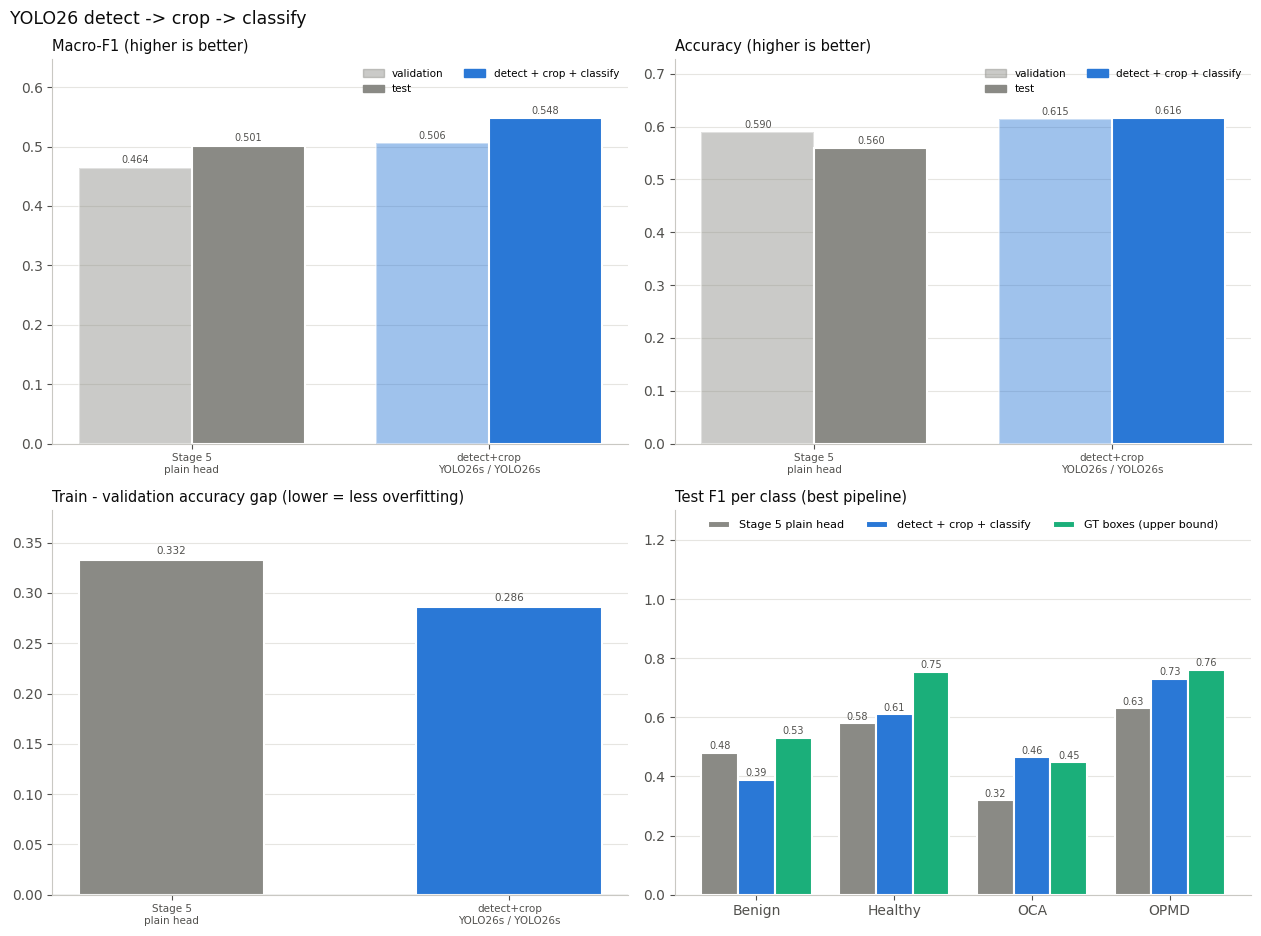

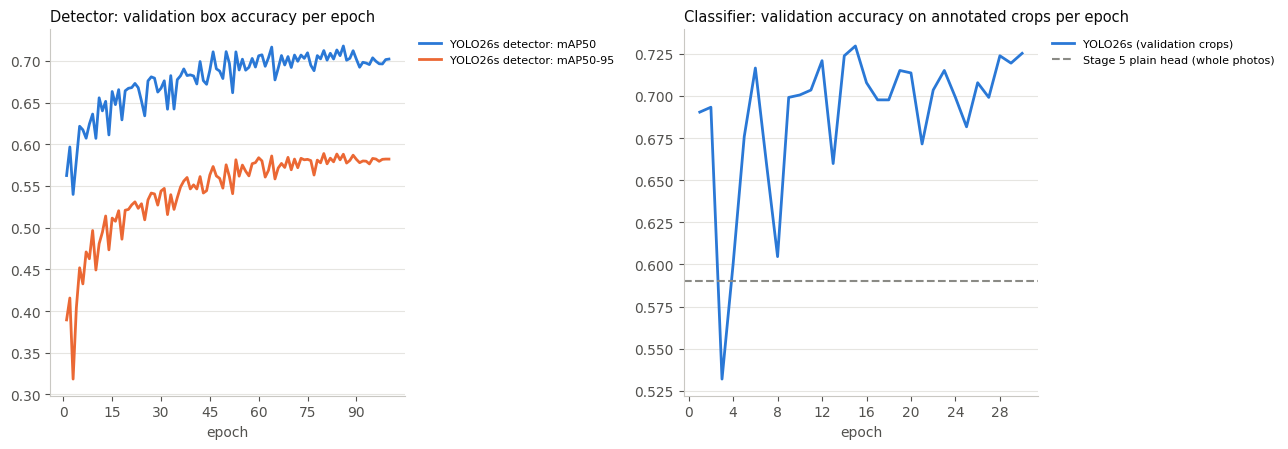

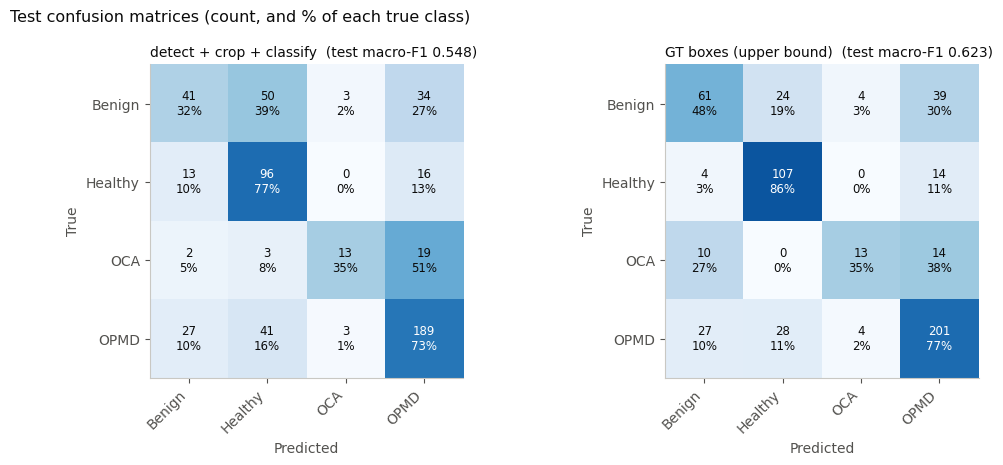

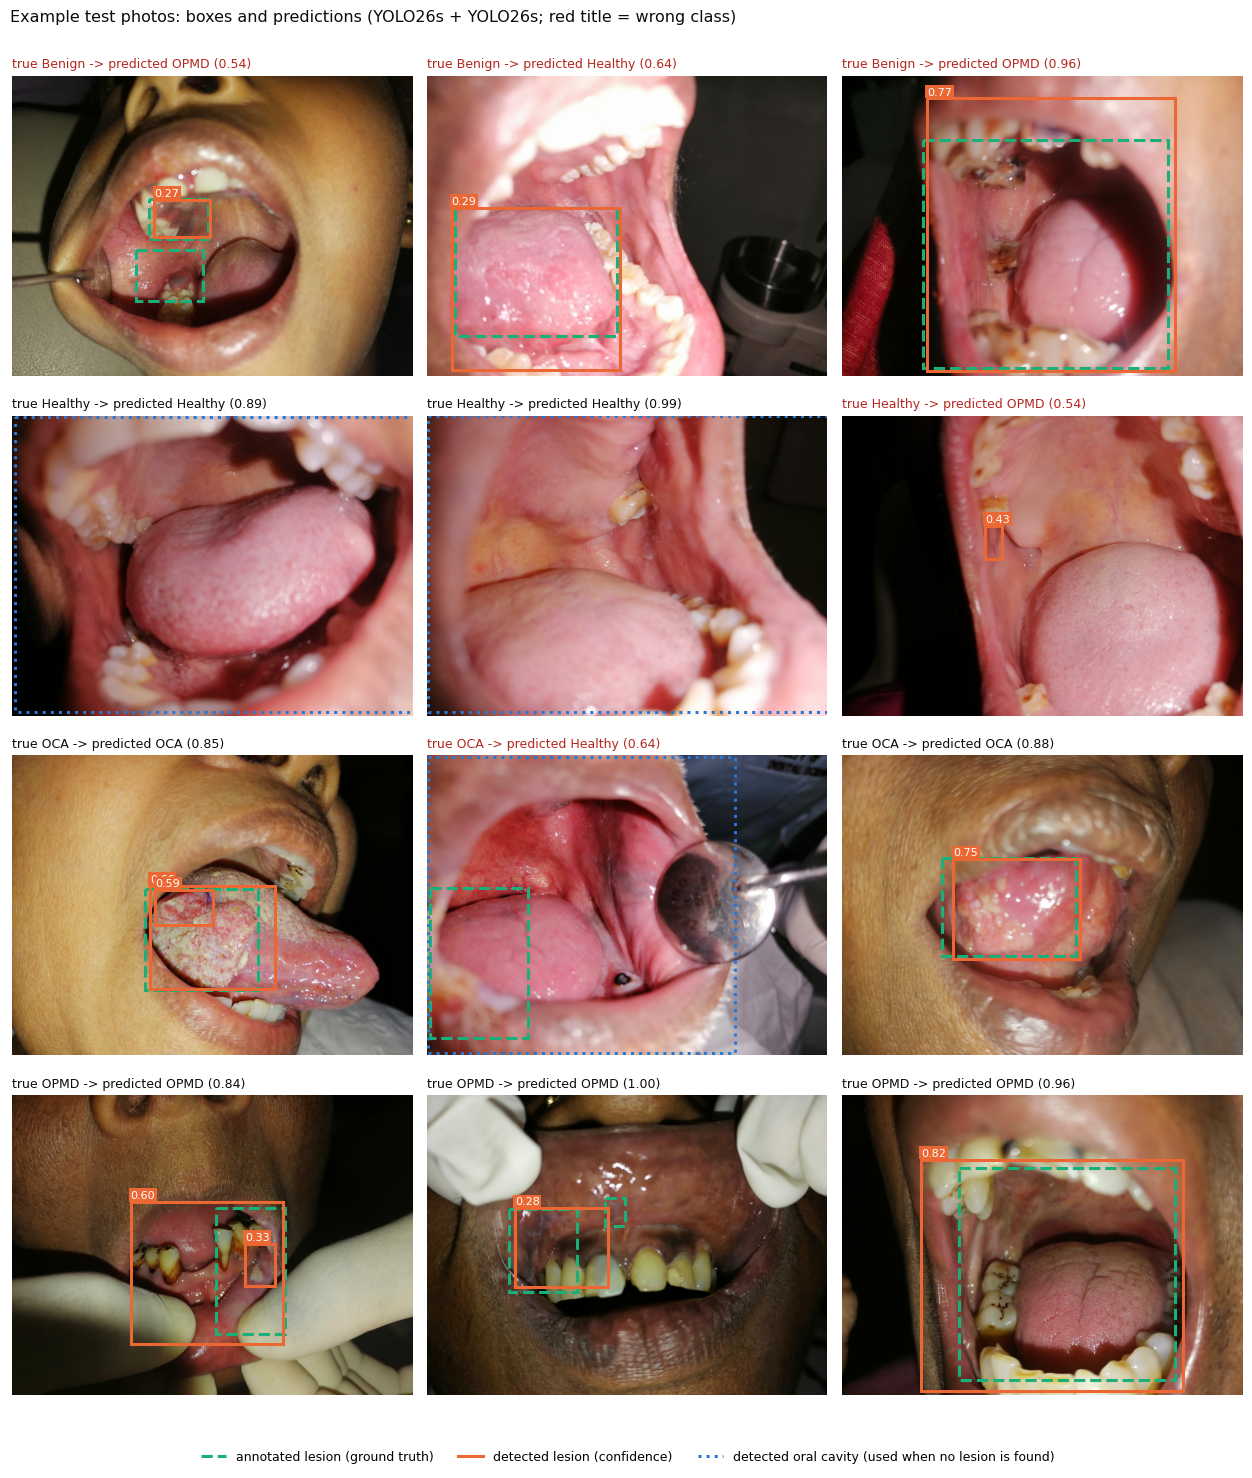

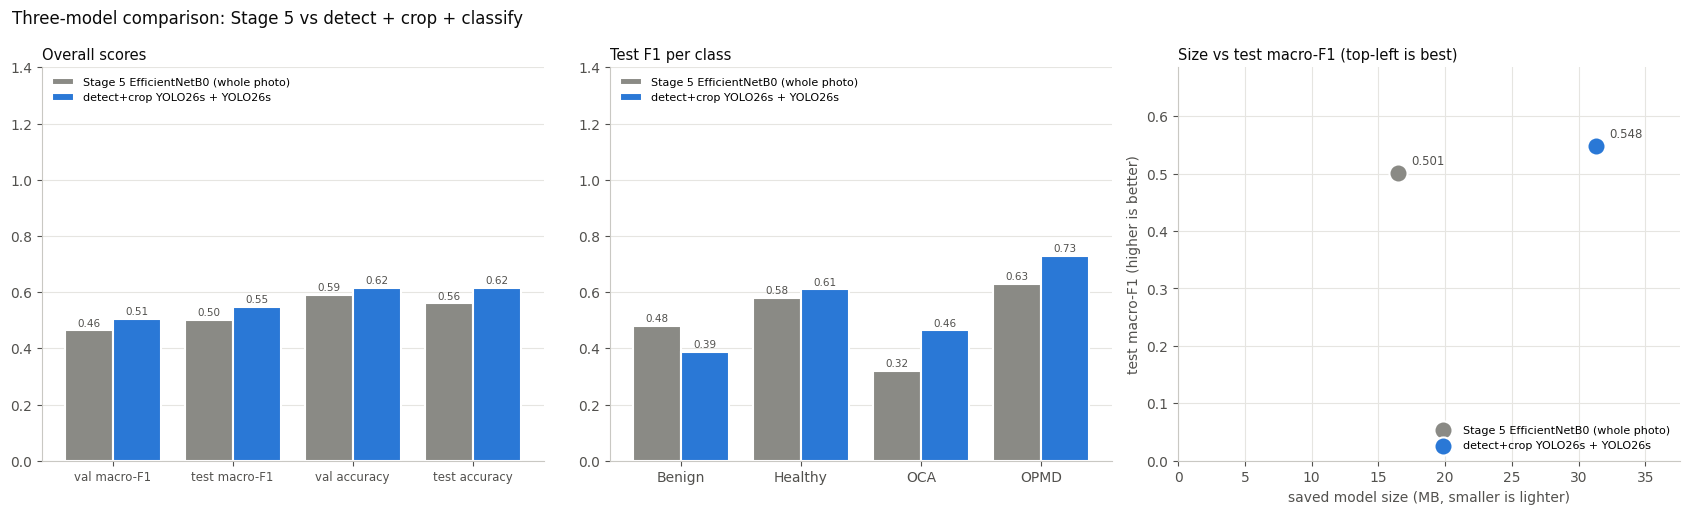


Best pipeline by VALIDATION macro-F1: YOLO26s + YOLO26s
  validation macro-F1 0.5059  (Stage 5 plain head 0.4641, +0.0418)
  test       macro-F1 0.5480  (Stage 5 plain head 0.5014, +0.0466)
  GT-box upper bound: val 0.6419 / test 0.6234

Reading the upper bound: with perfect boxes the same classifier reaches test macro-F1 0.623. The +0.075 difference to the real pipeline is what detector mistakes cost; a small difference means the detector is good enough and the classifier is the limit.

Caution: the validation set has only 16 'OCA' photos, and macro-F1 weights every class equally,
so the validation ranking moves a lot with a handful of predictions. Each result is a single training run, so differences of ~1-2 points are noise.
Train photos were seen by the detector during training, so the train/val gap of the pipeline is only a rough overfitting signal.

For the fusion notebooks use: det_yolo26s__cls_yolo26s_cls_embeddings.npy + det_yolo26s__cls_yolo26s_cls_embeddings_meta.csv


In [7]:
# ============================================================
# 7. FINAL RESULTS -- tables + graphs. The pipeline to carry forward is chosen by VALIDATION macro-F1
#    (tie-break: smaller train/val gap); test is shown but never used to choose.
# ============================================================
agg = results_df.sort_values(["val_macro_f1", "train_val_gap"], ascending=[False, True]).reset_index(drop=True)
agg.to_csv(OUTPUT_DIR / "detcls_final_results.csv", index=False)


def short(s):
    return s.replace("-cls", "").replace("yolo", "YOLO")


agg["label"] = agg.apply(lambda r: f"detect+crop\n{short(r['det'])} / {short(r['cls'])}", axis=1)
agg["kind"] = "pipe"

ref_rows = [dict(label="Stage 5\nplain head", kind="ref", **{k: v for k, v in STAGE5_REFERENCE.items() if not isinstance(v, dict)})]
if YOLO_WHOLE_IMAGE_CSV is not None and Path(YOLO_WHOLE_IMAGE_CSV).is_file():
    for _, a in pd.read_csv(YOLO_WHOLE_IMAGE_CSV).iterrows():
        ref_rows.append(dict(label=f"{short(a['model'])}\nwhole photo ({'segmented' if 'segmented' in str(a['dataset']) else 'unsegmented'})",
                             kind="whole", **{k: a[k] for k in ("val_accuracy", "val_macro_f1", "test_accuracy", "test_macro_f1", "train_val_gap")}))
OTHER = None
if OTHER_RUN_DIR is not None:
    _f = next(iter(sorted(Path(OTHER_RUN_DIR).rglob("detcls_final_results.csv"))), None)
    if _f is None:
        print(f"NOTE: no detcls_final_results.csv under OTHER_RUN_DIR={OTHER_RUN_DIR}; the other notebook is left out of the comparison.")
    else:
        _o = pd.read_csv(_f).sort_values(["val_macro_f1", "train_val_gap"], ascending=[False, True]).iloc[0]
        _mj = next(iter(sorted(Path(OTHER_RUN_DIR).rglob(f"{_o['tag']}_final_metrics.json"))), None)
        OTHER = dict(row=_o, report=(_json.load(open(_mj))["test_report"] if _mj else None))
        ref_rows.append(dict(label=f"detect+crop\n{short(_o['det'])} / {short(_o['cls'])}\n(other notebook)", kind="other",
                             **{k: _o[k] for k in ("val_accuracy", "val_macro_f1", "test_accuracy", "test_macro_f1", "train_val_gap")}))
ref_df = pd.DataFrame(ref_rows)
ents = pd.concat([ref_df, agg[["label", "kind", "val_accuracy", "val_macro_f1", "test_accuracy", "test_macro_f1", "train_val_gap"]]], ignore_index=True)

print("DETECTOR (lesion boxes; mAP/AP = box accuracy, 1.0 = perfect)\n")
_d = []
for stem, d in DET.items():
    for r in d["rows"]:
        _d.append(dict(detector=short(stem), split=r["split"], lesion_AP50=r["lesion_ap50"], oral_cavity_AP50=r["cavity_ap50"],
                       mAP50_95=r["map5095"], precision=r["precision"], recall=r["recall"]))
det_table = pd.DataFrame(_d)
det_table.to_csv(OUTPUT_DIR / "detector_metrics.csv", index=False)
print(det_table.round(3).to_string(index=False))

print("\n\nFULL PIPELINE (whole-photo 4-class result, ranked by VALIDATION macro-F1)\n")
show = agg.copy()
show["pipeline"] = show["label"].str.replace("\n", " ")
print(show[["pipeline", "val_macro_f1", "test_macro_f1", "val_accuracy", "test_accuracy", "train_val_gap"]].round(4).to_string(index=False))
print("\nHow the pipeline behaves (test photos):")
print(show[["pipeline", "lesion_sensitivity_test", "healthy_specificity_test", "test_no_lesion_found", "test_whole_photo_fallback"]]
      .rename(columns={"lesion_sensitivity_test": "lesion_found_when_present", "healthy_specificity_test": "no_lesion_when_healthy",
                       "test_no_lesion_found": "no_lesion_found", "test_whole_photo_fallback": "whole_photo_fallback"}).round(3).to_string(index=False))
print("\nUpper bound with annotated boxes (NOT a real result -- new photos have no annotations):")
print(show[["pipeline", "upper_val_macro_f1", "upper_test_macro_f1", "upper_test_accuracy"]].round(4).to_string(index=False))
print("\nReferences:")
print(ref_df.assign(label=ref_df["label"].str.replace("\n", " / "))[["label", "val_macro_f1", "test_macro_f1", "val_accuracy", "test_accuracy", "train_val_gap"]].round(4).to_string(index=False))

# ---------------- model sizes ----------------
size_rows = [dict(model="EfficientNetB0 (Stage 5, approx.)", params_M=STAGE5_REFERENCE["n_params"] / 1e6, file_mb=STAGE5_REFERENCE["file_mb"])]
for stem, d in DET.items():
    size_rows.append(dict(model=f"detector {short(stem)}", params_M=d["params"] / 1e6, file_mb=d["mb"]))
for stem, d in CLS.items():
    size_rows.append(dict(model=f"classifier {short(stem)}", params_M=d["params"] / 1e6, file_mb=d["mb"]))
for _, r in agg.iterrows():
    size_rows.append(dict(model=f"PIPELINE {short(r['det'])} + {short(r['cls'])} (both files)", params_M=r["total_params"] / 1e6, file_mb=r["total_mb"]))
size_tbl = pd.DataFrame(size_rows)
size_tbl["vs_EfficientNetB0"] = (size_tbl["file_mb"] / size_tbl["file_mb"].iloc[0]).map("{:.2f}x".format)
size_tbl[["params_M", "file_mb"]] = size_tbl[["params_M", "file_mb"]].round(2)
size_tbl.to_csv(OUTPUT_DIR / "detcls_model_sizes.csv", index=False)
print("\nMODEL SIZES (saved .pt files; YOLO files are stored in half precision, the EfficientNetB0 row is an estimate)")
print(size_tbl.to_string(index=False))
_sp = agg["pipeline_seconds"].iloc[0]
print(f"\nSpeed: the first pipeline took {_sp / len(imgs) * 1000:.0f} ms per photo for the classifier stage + cropping "
      f"(detector predictions for all photos are computed once and shared).")

# ---------------- style ----------------
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
COL = {"pipe": "#2a78d6", "whole": "#eb6834", "other": "#eb6834", "ref": "#8a8a85", "up": "#1baf7a"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c3",
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white"})
cols = [COL[k] for k in ents["kind"]]
xs = np.arange(len(ents))


def grouped(ax, metric, title):
    w = 0.38
    vals, tests = ents[f"val_{metric}"].values, ents[f"test_{metric}"].values
    for rects in (ax.bar(xs - w / 2, vals, w, color=cols, alpha=0.45, edgecolor="white", linewidth=1.5),
                  ax.bar(xs + w / 2, tests, w, color=cols, edgecolor="white", linewidth=1.5)):
        for r in rects:
            ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.004, f"{r.get_height():.3f}", ha="center", va="bottom", fontsize=7, color=INK2)
    ax.set_xticks(xs); ax.set_xticklabels(ents["label"], fontsize=7.5)
    ax.set_title(title, fontsize=10.5, loc="left"); ax.set_ylim(0, max(vals.max(), tests.max()) * 1.18)
    ax.grid(axis="x", visible=False)
    ax.legend(handles=[mpl.patches.Patch(color="#8a8a85", alpha=0.45, label="validation"), mpl.patches.Patch(color="#8a8a85", label="test"),
                       mpl.patches.Patch(color=COL["pipe"], label="detect + crop + classify")] +
                      ([mpl.patches.Patch(color=COL["whole"], label="YOLO26 whole photo")] if (ents["kind"] == "whole").any() else []) +
                      ([mpl.patches.Patch(color=COL["other"], label="detect + crop (other notebook)")] if (ents["kind"] == "other").any() else []),
              frameon=False, fontsize=7.5, loc="upper right", ncol=2)


best = agg.iloc[0]
fig, axes = plt.subplots(2, 2, figsize=(max(13, 1.0 * len(ents) + 6), 9.5))
grouped(axes[0, 0], "macro_f1", "Macro-F1 (higher is better)")
grouped(axes[0, 1], "accuracy", "Accuracy (higher is better)")
ax = axes[1, 0]
g = ents["train_val_gap"].values
ax.bar(xs, g, 0.55, color=cols, edgecolor="white", linewidth=1.5)
span = max(g.max() - min(g.min(), 0), 0.05)
for x, h in zip(xs, g):
    ax.text(x, h + (0.012 * span if h >= 0 else -0.012 * span), f"{h:.3f}", ha="center", va="bottom" if h >= 0 else "top", fontsize=7.5, color=INK2)
ax.axhline(0, color="#c9c8c3", lw=1)
ax.set_ylim(min(g.min(), 0) - 0.12 * span if g.min() < 0 else 0, max(g.max(), 0) + 0.15 * span)
ax.set_xticks(xs); ax.set_xticklabels(ents["label"], fontsize=7.5)
ax.set_title("Train - validation accuracy gap (lower = less overfitting)", fontsize=10.5, loc="left"); ax.grid(axis="x", visible=False)

_rep = _json.load(open(OUTPUT_DIR / f"{best['tag']}_final_metrics.json"))
series = {"Stage 5 plain head": ([STAGE5_REFERENCE["test_f1_by_class"].get(c, np.nan) for c in CLASS_NAMES], COL["ref"]),
          "detect + crop + classify": ([_rep["test_report"][c]["f1-score"] for c in CLASS_NAMES], COL["pipe"]),
          "GT boxes (upper bound)": ([_rep["upper_bound_test_report"][c]["f1-score"] for c in CLASS_NAMES], COL["up"])}
if OTHER is not None and OTHER["report"] is not None:
    _gt = series.pop("GT boxes (upper bound)")
    series["detect + crop (other notebook)"] = ([OTHER["report"][c]["f1-score"] for c in CLASS_NAMES], COL["other"])
    series["GT boxes (upper bound)"] = _gt
ax = axes[1, 1]
w = 0.8 / len(series); xc = np.arange(N_CLASSES)
for k, (nm, (vals, colr)) in enumerate(series.items()):
    for r in ax.bar(xc + (k - (len(series) - 1) / 2) * w, vals, w, color=colr, edgecolor="white", linewidth=1.5, label=nm):
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.005, f"{r.get_height():.2f}", ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(xc); ax.set_xticklabels(CLASS_NAMES); ax.set_ylim(0, 1.3); ax.grid(axis="x", visible=False)
ax.set_title("Test F1 per class (best pipeline)", fontsize=10.5, loc="left")
ax.legend(frameon=False, fontsize=8, ncol=2 if len(series) > 3 else 3, loc="upper center")
fig.suptitle("YOLO26 detect -> crop -> classify", fontsize=12.5, x=0.01, ha="left", color=INK)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "detcls_fig1_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- learning curves ----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for stem, d in DET.items():
    h = d["hist"]
    axes[0].plot(h["epoch"], h["metrics/mAP50(B)"], color=COL["pipe"], lw=2, label=f"{short(stem)} detector: mAP50")
    axes[0].plot(h["epoch"], h["metrics/mAP50-95(B)"], color=COL["whole"], lw=2, label=f"{short(stem)} detector: mAP50-95")
axes[0].set_title("Detector: validation box accuracy per epoch", fontsize=10.5, loc="left")
_palette = [COL["pipe"], COL["whole"], COL["up"]]
for k, (stem, d) in enumerate(CLS.items()):
    axes[1].plot(d["hist"]["epoch"], d["hist"]["metrics/accuracy_top1"], color=_palette[k % 3], lw=2, label=f"{short(stem)} (validation crops)")
axes[1].axhline(STAGE5_REFERENCE["val_accuracy"], color="#8a8a85", ls="--", lw=1.5, label="Stage 5 plain head (whole photos)")
axes[1].set_title("Classifier: validation accuracy on annotated crops per epoch", fontsize=10.5, loc="left")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(axis="x", visible=False)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
    ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "detcls_fig2_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- confusion matrices: real pipeline vs GT-box upper bound ----------------
_te = (imgs["split"] == "test").values
_pipe = PIPES[(best["det"], best["cls"])]
_ytrue = imgs.loc[_te, "category"].values
panels = [("detect + crop + classify", [CLASS_NAMES[i] for i in _pipe["probs"][_te].argmax(axis=1)], best["test_macro_f1"]),
          ("GT boxes (upper bound)", [CLASS_NAMES[i] for i in UPPER[best["cls"]]["probs"][_te].argmax(axis=1)], best["upper_test_macro_f1"])]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.7))
for ax, (nm, pred, f1) in zip(axes, panels):
    cm = confusion_matrix(_ytrue, pred, labels=CLASS_NAMES)
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f"{cm[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center", fontsize=8.5, color="white" if norm[i, j] > 0.55 else INK)
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.grid(False)
    ax.set_title(f"{nm}  (test macro-F1 {f1:.3f})", fontsize=10, loc="left")
fig.suptitle("Test confusion matrices (count, and % of each true class)", fontsize=11.5, x=0.01, ha="left", color=INK)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "detcls_fig3_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- example detections (bounding boxes) ----------------
C_GT, C_PRED, C_CAV = "#1baf7a", "#eb6834", "#2a78d6"
rng_plot = np.random.default_rng(0)
test_idx = np.where(_te)[0]
per_class = 3
fig, axes = plt.subplots(N_CLASSES, per_class, figsize=(4.2 * per_class, 3.7 * N_CLASSES), squeeze=False)
for ci, cname in enumerate(CLASS_NAMES):
    pool = [i for i in test_idx if imgs.loc[i, "category"] == cname]
    pick = list(rng_plot.choice(pool, size=min(per_class, len(pool)), replace=False)) if pool else []
    for cj in range(per_class):
        ax = axes[ci, cj]; ax.axis("off")
        if cj >= len(pick):
            continue
        i = int(pick[cj]); r = imgs.loc[i]
        ax.imshow(Image.open(r["path"]).convert("RGB"))
        for b in r["lesions"]:
            ax.add_patch(mpl.patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=C_GT, lw=2.2, ls="--"))
        kind = _pipe["kinds"][i]
        for c, b in _pipe["boxes"][i]:
            if kind == "whole":
                continue
            ax.add_patch(mpl.patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False,
                                               ec=C_PRED if kind == "lesion" else C_CAV, lw=2.2, ls="-" if kind == "lesion" else ":"))
            if kind == "lesion":
                ax.text(b[0], max(b[1] - 6, 0), f"{c:.2f}", color="white", fontsize=8, va="bottom",
                        bbox=dict(facecolor=C_PRED, edgecolor="none", pad=1.2))
        pr = _pipe["probs"][i]
        ok = CLASS_NAMES[int(pr.argmax())] == cname
        ax.set_title(f"true {cname} -> predicted {CLASS_NAMES[int(pr.argmax())]} ({pr.max():.2f})", fontsize=9,
                     color=INK if ok else "#b3261e", loc="left")
handles = [mpl.lines.Line2D([], [], color=C_GT, lw=2.2, ls="--", label="annotated lesion (ground truth)"),
           mpl.lines.Line2D([], [], color=C_PRED, lw=2.2, label="detected lesion (confidence)"),
           mpl.lines.Line2D([], [], color=C_CAV, lw=2.2, ls=":", label="detected oral cavity (used when no lesion is found)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle(f"Example test photos: boxes and predictions ({short(best['det'])} + {short(best['cls'])}; red title = wrong class)",
             fontsize=11.5, x=0.01, ha="left", color=INK)
plt.tight_layout(rect=(0, 0.02, 1, 0.98))
fig.savefig(OUTPUT_DIR / "detcls_fig4_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- three-model comparison: Stage 5 vs the two best pipelines ----------------
_c3 = [dict(label="Stage 5\nEfficientNetB0 (whole photo)", color=COL["ref"], val_f1=STAGE5_REFERENCE["val_macro_f1"],
            test_f1=STAGE5_REFERENCE["test_macro_f1"], val_acc=STAGE5_REFERENCE["val_accuracy"], test_acc=STAGE5_REFERENCE["test_accuracy"],
            per_class=[STAGE5_REFERENCE["test_f1_by_class"].get(c, np.nan) for c in CLASS_NAMES], mb=STAGE5_REFERENCE["file_mb"])]
_n_here = 1 if (OTHER is not None and OTHER["report"] is not None) else 2
for _k, (_, _r) in enumerate(agg.head(_n_here).iterrows()):
    _m = _json.load(open(OUTPUT_DIR / f"{_r['tag']}_final_metrics.json"))
    _c3.append(dict(label=f"detect+crop\n{short(_r['det'])} + {short(_r['cls'])}", color=[COL["pipe"], COL["whole"]][_k],
                    val_f1=_r["val_macro_f1"], test_f1=_r["test_macro_f1"], val_acc=_r["val_accuracy"], test_acc=_r["test_accuracy"],
                    per_class=[_m["test_report"][c]["f1-score"] for c in CLASS_NAMES], mb=_r["total_mb"]))
if _n_here == 1:
    _o = OTHER["row"]
    _c3.append(dict(label=f"detect+crop\n{short(_o['det'])} + {short(_o['cls'])}\n(other notebook)", color=COL["whole"],
                    val_f1=_o["val_macro_f1"], test_f1=_o["test_macro_f1"], val_acc=_o["val_accuracy"], test_acc=_o["test_accuracy"],
                    per_class=[OTHER["report"][c]["f1-score"] for c in CLASS_NAMES], mb=_o["total_mb"]))
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
ax = axes[0]
_x = np.arange(4); _w = 0.8 / len(_c3)
_names = ["val macro-F1", "test macro-F1", "val accuracy", "test accuracy"]
for k, m in enumerate(_c3):
    vals = [m["val_f1"], m["test_f1"], m["val_acc"], m["test_acc"]]
    for r in ax.bar(_x + (k - (len(_c3) - 1) / 2) * _w, vals, _w, color=m["color"], edgecolor="white", linewidth=1.5, label=m["label"].replace("\n", " ")):
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.008, f"{r.get_height():.2f}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(_x); ax.set_xticklabels(_names, fontsize=8.5); ax.set_ylim(0, 1.4); ax.grid(axis="x", visible=False)
ax.set_title("Overall scores", fontsize=10.5, loc="left"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax = axes[1]
_x = np.arange(N_CLASSES)
for k, m in enumerate(_c3):
    for r in ax.bar(_x + (k - (len(_c3) - 1) / 2) * _w, m["per_class"], _w, color=m["color"], edgecolor="white", linewidth=1.5, label=m["label"].replace("\n", " ")):
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.008, f"{r.get_height():.2f}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(_x); ax.set_xticklabels(CLASS_NAMES); ax.set_ylim(0, 1.4); ax.grid(axis="x", visible=False)
ax.set_title("Test F1 per class", fontsize=10.5, loc="left"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax = axes[2]
for m in _c3:
    ax.scatter(m["mb"], m["test_f1"], s=170, color=m["color"], edgecolor="white", linewidth=1.5, zorder=3, label=m["label"].replace("\n", " "))
    ax.annotate(f"{m['test_f1']:.3f}", (m["mb"], m["test_f1"]), textcoords="offset points", xytext=(9, 6), fontsize=8.5, color=INK2)
ax.set_xlabel("saved model size (MB, smaller is lighter)"); ax.set_ylabel("test macro-F1 (higher is better)")
ax.set_xlim(0, max(m["mb"] for m in _c3) * 1.2); ax.set_ylim(0, max(m["test_f1"] for m in _c3) * 1.25)
ax.set_title("Size vs test macro-F1 (top-left is best)", fontsize=10.5, loc="left"); ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Three-model comparison: Stage 5 vs detect + crop + classify", fontsize=12, x=0.01, ha="left", color=INK)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "detcls_fig5_three_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- verdict ----------------
print("\n" + "=" * 72)
print(f"Best pipeline by VALIDATION macro-F1: {short(best['det'])} + {short(best['cls'])}")
print(f"  validation macro-F1 {best['val_macro_f1']:.4f}  (Stage 5 plain head {STAGE5_REFERENCE['val_macro_f1']:.4f}, "
      f"{best['val_macro_f1'] - STAGE5_REFERENCE['val_macro_f1']:+.4f})")
print(f"  test       macro-F1 {best['test_macro_f1']:.4f}  (Stage 5 plain head {STAGE5_REFERENCE['test_macro_f1']:.4f}, "
      f"{best['test_macro_f1'] - STAGE5_REFERENCE['test_macro_f1']:+.4f})")
print(f"  GT-box upper bound: val {best['upper_val_macro_f1']:.4f} / test {best['upper_test_macro_f1']:.4f}")
print("=" * 72)
_gap = best["upper_test_macro_f1"] - best["test_macro_f1"]
print(f"\nReading the upper bound: with perfect boxes the same classifier reaches test macro-F1 {best['upper_test_macro_f1']:.3f}. "
      f"The {_gap:+.3f} difference to the real pipeline is what detector mistakes cost; a small difference means the detector is good enough and "
      f"the classifier is the limit.")
_br = _rep["val_report"]
_small = min(CLASS_NAMES, key=lambda c: _br[c]["support"])
print(f"\nCaution: the validation set has only {int(_br[_small]['support'])} '{_small}' photos, and macro-F1 weights every class equally,")
print("so the validation ranking moves a lot with a handful of predictions. Each result is a single training run, so differences of ~1-2 points are noise.")
print("Train photos were seen by the detector during training, so the train/val gap of the pipeline is only a rough overfitting signal.")
(OUTPUT_DIR / "best_pipeline.json").write_text(_json.dumps({"best_by_val_macro_f1": best["tag"]}, indent=2))
print(f"\nFor the fusion notebooks use: {best['tag']}_embeddings.npy + {best['tag']}_embeddings_meta.csv")


In [8]:
# ============================================================
# 8. METRICS SUMMARY -- the same fields in every YOLO notebook, so two runs can be compared side by side later.
#    Saved as summary_<detector>.csv (one row, wide) and summary_<detector>.json (full detail).
# ============================================================
def _num(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else float(x)

_rows, _full = [], {}
for _, r in agg.iterrows():
    ds, cs = r["det"], r["cls"]
    m = _json.load(open(OUTPUT_DIR / f"{r['tag']}_final_metrics.json"))
    dv, dt = DET[ds]["rows"]
    row = {
        "pipeline": f"{ds} + {cs}", "detector": ds, "classifier": cs,
        # ---- whole-photo 4-class result (what matters) ----
        "val_accuracy": r["val_accuracy"], "val_macro_f1": r["val_macro_f1"],
        "test_accuracy": r["test_accuracy"], "test_macro_f1": r["test_macro_f1"],
        "train_accuracy": r["train_accuracy"], "train_val_gap": r["train_val_gap"],
        "test_weighted_f1": m["test_report"]["weighted avg"]["f1-score"],
    }
    for c in CLASS_NAMES:
        for sp in ("val", "test"):
            rep = m[f"{sp}_report"][c]
            row[f"{sp}_{c}_precision"], row[f"{sp}_{c}_recall"], row[f"{sp}_{c}_f1"], row[f"{sp}_{c}_n"] = (
                rep["precision"], rep["recall"], rep["f1-score"], int(rep["support"]))
    row.update({
        # ---- detector (lesion localisation) ----
        "det_val_lesion_AP50": dv["lesion_ap50"], "det_test_lesion_AP50": dt["lesion_ap50"],
        "det_val_mAP50_95": dv["map5095"], "det_test_mAP50_95": dt["map5095"],
        "det_test_precision": dt["precision"], "det_test_recall": dt["recall"],
        "det_val_cavity_AP50": dv["cavity_ap50"], "det_test_cavity_AP50": dt["cavity_ap50"],
        "lesion_found_when_present_test": r["lesion_sensitivity_test"], "no_lesion_when_healthy_test": r["healthy_specificity_test"],
        "test_no_lesion_found": r["test_no_lesion_found"], "test_whole_photo_fallback": r["test_whole_photo_fallback"],
        # ---- upper bound with annotated boxes (not a real result) ----
        "gtbox_upper_val_macro_f1": r["upper_val_macro_f1"], "gtbox_upper_test_macro_f1": r["upper_test_macro_f1"],
        "gtbox_upper_test_accuracy": r["upper_test_accuracy"],
        # ---- model size and cost ----
        "det_params_M": r["det_params"] / 1e6, "cls_params_M": r["cls_params"] / 1e6, "total_params_M": r["total_params"] / 1e6,
        "det_file_mb": r["det_mb"], "cls_file_mb": r["cls_mb"], "total_file_mb": r["total_mb"],
        "det_epochs": len(DET[ds]["hist"]), "cls_epochs": len(CLS[cs]["hist"]),
        "cls_best_val_crop_accuracy": float(CLS[cs]["hist"]["metrics/accuracy_top1"].max()),
        "train_minutes_total": _num(r["train_minutes"]), "pipeline_seconds_per_photo_after_detection": r["pipeline_seconds"] / r["n_images"],
        # ---- data ----
        "n_photos": int(r["n_images"]), "n_train": int((imgs.split == "train").sum()), "n_val": int((imgs.split == "val").sum()), "n_test": int((imgs.split == "test").sum()),
        "conf_thr": CONF_THR, "top_k": TOP_K, "det_imgsz": DET_IMGSZ, "cls_imgsz": CLS_IMGSZ, "seed": SEED,
    })
    _rows.append(row)
    _full[r["tag"]] = dict(summary=row, val_report=m["val_report"], test_report=m["test_report"], upper_bound_test_report=m["upper_bound_test_report"],
                           detector_val=dv, detector_test=dt)

summary = pd.DataFrame(_rows)
_name = f"summary_{agg.iloc[0]['det']}"
summary.to_csv(OUTPUT_DIR / f"{_name}.csv", index=False)
(OUTPUT_DIR / f"{_name}.json").write_text(_json.dumps(_full, indent=2, default=str))

pd.set_option("display.width", 200)
print("=" * 78); print("METRICS SUMMARY"); print("=" * 78)
for row in _rows:
    print(f"\nPipeline: {row['pipeline']}   ({row['n_train']} train / {row['n_val']} val / {row['n_test']} test photos)")
    print("\n1) Whole-photo 4-class result")
    print(pd.DataFrame({"validation": [row["val_accuracy"], row["val_macro_f1"]], "test": [row["test_accuracy"], row["test_macro_f1"]]},
                       index=["accuracy", "macro-F1"]).round(4).to_string())
    print(f"   train accuracy {row['train_accuracy']:.4f}   train-val gap {row['train_val_gap']:+.4f}   Stage 5 for reference: "
          f"val macro-F1 {STAGE5_REFERENCE['val_macro_f1']:.4f}, test macro-F1 {STAGE5_REFERENCE['test_macro_f1']:.4f}")
    print("\n2) Per class (test | validation)")
    pc = pd.DataFrame({sp: {c: dict(precision=row[f"{sp}_{c}_precision"], recall=row[f"{sp}_{c}_recall"], f1=row[f"{sp}_{c}_f1"], n=row[f"{sp}_{c}_n"])
                            for c in CLASS_NAMES} for sp in ("test", "val")})
    out = pd.DataFrame({f"{sp}_{k}": [pc.loc[c, sp][k] for c in CLASS_NAMES] for sp in ("test", "val") for k in ("precision", "recall", "f1", "n")}, index=CLASS_NAMES)
    print(out.round(3).to_string())
    print("\n3) Detector (finds the lesion)")
    print(pd.DataFrame({"validation": [row["det_val_lesion_AP50"], row["det_val_mAP50_95"], row["det_val_cavity_AP50"]],
                        "test": [row["det_test_lesion_AP50"], row["det_test_mAP50_95"], row["det_test_cavity_AP50"]]},
                       index=["Lesion AP50", "mAP50-95 (both classes)", "Oral-cavity AP50"]).round(3).to_string())
    print(f"   test: lesion found when present {row['lesion_found_when_present_test']:.3f}, no lesion on Healthy photos {row['no_lesion_when_healthy_test']:.3f}; "
          f"photos with no lesion found {row['test_no_lesion_found']:.3f}, whole-photo fallback {row['test_whole_photo_fallback']:.3f}")
    print(f"   with annotated boxes (upper bound, not a real result): val macro-F1 {row['gtbox_upper_val_macro_f1']:.4f}, test macro-F1 {row['gtbox_upper_test_macro_f1']:.4f}")
    print("\n4) Size and cost")
    print(pd.DataFrame({"parameters (M)": [row["det_params_M"], row["cls_params_M"], row["total_params_M"]],
                        "file (MB)": [row["det_file_mb"], row["cls_file_mb"], row["total_file_mb"]]},
                       index=["detector", "classifier", "pipeline total"]).round(2).to_string())
    print(f"   epochs: detector {row['det_epochs']}, classifier {row['cls_epochs']} (best val crop accuracy {row['cls_best_val_crop_accuracy']:.3f}); "
          f"training time {row['train_minutes_total'] if row['train_minutes_total'] is not None else 'n/a'} min; "
          f"classify+crop {row['pipeline_seconds_per_photo_after_detection'] * 1000:.0f} ms per photo (after detection)")
print(f"\nSaved: {_name}.csv (one row per pipeline, same columns in every YOLO notebook) and {_name}.json (full per-class reports).")
print("To compare two runs later: pd.concat([pd.read_csv('summary_yolo26n.csv'), pd.read_csv('summary_yolo26s.csv')]) -- same columns.")


METRICS SUMMARY

Pipeline: yolo26s + yolo26s-cls   (1933 train / 517 val / 550 test photos)

1) Whole-photo 4-class result
          validation    test
accuracy      0.6151  0.6164
macro-F1      0.5059  0.5480
   train accuracy 0.9012   train-val gap +0.2861   Stage 5 for reference: val macro-F1 0.4641, test macro-F1 0.5014

2) Per class (test | validation)
         test_precision  test_recall  test_f1  test_n  val_precision  val_recall  val_f1  val_n
Benign            0.494        0.320    0.389     128          0.597       0.359   0.449    128
Healthy           0.505        0.768    0.610     125          0.542       0.675   0.601    123
OCA               0.684        0.351    0.464      37          0.500       0.188   0.273     16
OPMD              0.733        0.727    0.730     260          0.662       0.744   0.701    250

3) Detector (finds the lesion)
                         validation   test
Lesion AP50                   0.430  0.387
mAP50-95 (both classes)       0.588  0.573

## Done

Per pipeline `<tag>` (for example `det_yolo26n__cls_yolo26n_cls`): `<tag>_embeddings.npy` + `<tag>_embeddings_meta.csv` (fusion input),
`<tag>_probabilities.csv` (also lists which crops/boxes were used for each photo), `<tag>_detector_best.pt`,
`<tag>_classifier_best.pt`, `<tag>_model_config.json`, `<tag>_final_metrics.json`, `<tag>_test_predictions.csv`, epoch histories.

Overall: `fusion_manifest.json`, `detcls_runs_summary.csv`, `detcls_final_results.csv`, `detector_metrics.csv`, `detcls_model_sizes.csv`, `summary_<detector>.csv` + `.json` (the comparison-ready metrics, same columns in every YOLO notebook),
`detcls_fig1_metrics.png`, `detcls_fig2_curves.png`, `detcls_fig3_confusion.png`, `detcls_fig4_examples.png`,
`detcls_fig5_three_model_comparison.png`, `best_pipeline.json`.
The folder `detcls_runs/` holds Ultralytics' own plots (PR curves, confusion matrices, validation predictions with boxes).

Next: run the **fusion-attention notebook** on the best pipeline's embeddings and compare with the whole-photo embeddings.
